# Reconstructing a portrait from random pixels (FISTA)

The earlier notebooks of this module used small synthetic signals that were
exactly sparse. Here we run the full compressed-sensing pipeline on a real
64×64 photograph, which is only approximately sparse in the DCT basis. We
keep a random fraction of the pixels, fill in the rest with FISTA, and then
ask an honest question: is this actually better than simple interpolation?
The answer is "no" for clean pixels, and "yes" for a single-pixel camera with
a noisy detector. Seeing both cases tells you when compressed sensing is the
right tool.

**In this notebook you will**

* apply the measurement matrix and its transpose without ever forming them
  (a matrix-free operator built from the fast DCT);
* reconstruct the portrait from 10 %, 20 %, 40 % and 80 % of its pixels and
  measure the quality with PSNR;
* compare against two baselines: mean filling and linear interpolation;
* sweep the lasso weight $\lambda$ and see how it trades data fit for sparsity;
* simulate a single-pixel camera with detector noise and see where
  compressed sensing wins.

**Before this notebook:** `cs_recovery_fista` (the FISTA algorithm on a 1-D
signal) and `cs_uniform_vs_random` (why the samples are random).
**Next:** `osp_qr_illustrations` (choosing *where* to measure instead of
measuring at random).

**Runtime:** about 5 s on a laptop.

## The problem and the algorithm

Stack the $n$ pixels of the image into a vector $\boldsymbol{x}\in\mathbb{R}^n$
(here $n=64^2=4096$, brightness scaled to $[0,1]$). Write
$\boldsymbol{x}=\boldsymbol{\Psi}\boldsymbol{s}$, where $\boldsymbol{\Psi}$ is
the orthonormal inverse 2-D DCT (its columns are cosine patterns) and
$\boldsymbol{s}$ holds the DCT coefficients. Natural images are
*compressible*: most of their energy sits in a few coefficients of
$\boldsymbol{s}$.

We measure $m$ pixels. The measurement matrix $\mathbf{C}\in\mathbb{R}^{m\times n}$
is a random selection of $m$ rows of the identity, so
$\boldsymbol{y}=\mathbf{C}\boldsymbol{x}$ simply lists the kept pixel values.
We then solve the lasso

$$\hat{\boldsymbol{s}}=\arg\min_{\boldsymbol{s}}\ \tfrac12\|\boldsymbol{y}-
  \boldsymbol{\Phi}\boldsymbol{s}\|_2^2+\lambda\|\boldsymbol{s}\|_1,\qquad
  \boldsymbol{\Phi}=\mathbf{C}\boldsymbol{\Psi},\qquad
  \hat{\boldsymbol{x}}=\boldsymbol{\Psi}\hat{\boldsymbol{s}}.$$

The first term asks the reconstruction to agree with the measured pixels.
The second term, weighted by $\lambda>0$, asks for few nonzero DCT
coefficients.

We solve it with FISTA. Let $f(\boldsymbol{s})=\tfrac12\|\boldsymbol{y}-\boldsymbol{\Phi}\boldsymbol{s}\|_2^2$
be the smooth part, with gradient
$\nabla f(\boldsymbol{s})=\boldsymbol{\Phi}^\top(\boldsymbol{\Phi}\boldsymbol{s}-\boldsymbol{y})$.
Starting from $\boldsymbol{s}^0=\boldsymbol{z}^0=\boldsymbol{0}$ and $t_0=1$, each iteration is

$$\boldsymbol{v}^{k}=\boldsymbol{z}^{k}-\tfrac1L\nabla f(\boldsymbol{z}^{k}),\quad
  \boldsymbol{s}^{k+1}=\mathcal{S}_{\lambda/L}(\boldsymbol{v}^{k}),\quad
  t_{k+1}=\tfrac{1+\sqrt{1+4t_k^2}}{2},\quad
  \boldsymbol{z}^{k+1}=\boldsymbol{s}^{k+1}+\tfrac{t_k-1}{t_{k+1}}
  (\boldsymbol{s}^{k+1}-\boldsymbol{s}^{k}).$$

Here $L$ is the step-size constant (the largest eigenvalue of
$\boldsymbol{\Phi}^\top\boldsymbol{\Phi}$), $\mathcal{S}_a(v)=\mathrm{sign}(v)\max(|v|-a,0)$
is soft thresholding applied entry by entry, $\boldsymbol{z}^k$ is the
extrapolated point and $t_k$ the momentum weight.

**Matrix-free operator.** $\boldsymbol{\Phi}$ would be a $m\times 4096$ dense
matrix, but we never build it. Applying $\boldsymbol{\Phi}$ to coefficients
$\boldsymbol{s}$ means: inverse DCT (giving an image), then pick the sampled
pixels. Applying $\boldsymbol{\Phi}^\top$ to a residual means: scatter the
values into an empty (all-zero) image at the sampled positions, then take
the DCT. Both cost one fast transform.

**Why $L=1$.** $\boldsymbol{\Psi}$ is orthonormal, so it does not change
lengths. $\mathbf{C}$ only keeps some entries, so it can shorten a vector but
never lengthen it. Together $\|\boldsymbol{\Phi}\|_2=1$, hence $L=\|\boldsymbol{\Phi}\|_2^2=1$,
and the gradient step needs no tuning.

The next cell imports the libraries. `dctn` and `idctn` with `norm='ortho'`
are the orthonormal 2-D DCT and its inverse, `griddata` does the
interpolation baseline, and `save_dual` (a course helper) saves each figure in
a light and a dark version.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn, idctn
from scipy.interpolate import griddata
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
DATA = os.path.abspath(os.path.join('..', 'data'))

## Parameters (edit these)

* `SEED`: seed of the random generator (pixel masks, mirror patterns).
* `SIDE`: the image is resized to `SIDE`×`SIDE`, so $n=$ `SIDE`$^2$.
* `RATES`: fractions $m/n$ of pixels measured in Section 1.
* `LAM`: the lasso weight $\lambda$ used in Section 1.
* `N_ITER`: number of FISTA iterations.
* `LAM_SWEEP`, `RATE_SWEEP`: the values of $\lambda$ tried in Section 2, and
  the sampling rate at which they are tried.

The cell also loads the portrait as grayscale and scales it to $[0,1]$.

In [2]:
SEED = 0
SIDE = 64                       # image is SIDE x SIDE (n = SIDE^2 pixels)
RATES = [0.10, 0.20, 0.40, 0.80]   # fractions of pixels measured
LAM = 0.01                      # lasso weight (image scaled to [0, 1])
N_ITER = 300                    # FISTA iterations
LAM_SWEEP = np.logspace(-4, 0, 17)    # lambda sweep at RATE_SWEEP
RATE_SWEEP = 0.20

rng = np.random.default_rng(SEED)
img = np.asarray(Image.open(os.path.join(DATA, 'portrait.png')).convert('L')
                 .resize((SIDE, SIDE), Image.LANCZOS), float) / 255.0   # grayscale in [0, 1]
n = img.size
print(f"image {img.shape}, n = {n}")

image (64, 64), n = 4096


## Building blocks

This cell defines the tools used throughout:

* `soft_threshold(z, a)` is $\mathcal{S}_a$: it shrinks every entry towards
  zero by $a$ and sets entries with $|z|\le a$ exactly to zero. This is what
  produces sparse coefficients.
* `fista_pixels(y, mask, lam)` runs FISTA with the matrix-free
  $\boldsymbol{\Phi}$. The boolean array `mask` marks the sampled pixels (it
  plays the role of $\mathbf{C}$) and `y` holds their values. With
  `track=True` it also records the lasso objective at every iteration, so we
  can check convergence.
* `psnr(a, b)` is the peak signal-to-noise ratio,
  $\mathrm{PSNR}=10\log_{10}\!\big(1/\mathrm{MSE}\big)$ dB, where
  $\mathrm{MSE}$ is the mean squared pixel error and $1$ is the peak brightness.
  Higher is better, and because of the logarithm a gain of a few dB is
  already a clearly visible improvement.
* `relerr(a, b)` is the relative error $\|\hat{\boldsymbol{x}}-\boldsymbol{x}\|_2/\|\boldsymbol{x}\|_2$.

In [3]:
def soft_threshold(z, a):
    return np.sign(z) * np.maximum(np.abs(z) - a, 0.0)


def fista_pixels(y, mask, lam, n_iter=N_ITER, L=1.0, track=False):
    """Lasso in the 2-D DCT basis from the pixels where mask is True."""
    s = np.zeros(mask.shape); z = s.copy(); t = 1.0; hist = []
    for _ in range(n_iter):
        r = idctn(z, norm='ortho')[mask] - y              # Phi z - y
        g = np.zeros(mask.shape); g[mask] = r             # scatter residual into an empty image
        v = z - dctn(g, norm='ortho') / L                 # z - Phi^T r / L
        s_new = soft_threshold(v, lam / L)
        t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
        z = s_new + (t - 1) / t_new * (s_new - s)         # momentum (extrapolation) step
        s, t = s_new, t_new
        if track:
            res = idctn(s, norm='ortho')[mask] - y
            hist.append(0.5 * res @ res + lam * np.abs(s).sum())   # lasso objective
    return (s, np.array(hist)) if track else s


def psnr(a, b):
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))


def relerr(a, b):
    return np.linalg.norm(a - b) / np.linalg.norm(b)

**Checking $L=1$ numerically.** Power iteration repeatedly applies
$\boldsymbol{\Phi}^\top\boldsymbol{\Phi}$ to a random start and normalises.
The normalising factor converges to the largest eigenvalue, which is
$\|\boldsymbol{\Phi}\|_2^2$. We use a random 30 % mask; the assert confirms the
value is 1, so the fixed step $1/L=1$ is safe.

In [4]:
# sanity: ||Phi||_2 = 1 (power iteration on Phi^T Phi)
mask0 = rng.random(img.shape) < 0.3
v = rng.standard_normal(img.shape)
for _ in range(30):
    g = np.zeros(img.shape); g[mask0] = idctn(v, norm='ortho')[mask0]   # Phi v, scattered back
    v = dctn(g, norm='ortho'); nv = np.linalg.norm(v); v /= nv          # Phi^T (Phi v), normalise
assert abs(nv - 1.0) < 1e-6, "the step size L = ||Phi||^2 must be 1"

## 1. Reconstruction at four sampling rates

For each rate in `RATES` we draw a fresh random mask, keep those pixels as
$\boldsymbol{y}$, and build three reconstructions from the *same* pixels:

1. **FISTA with the DCT prior** (`LAM` = $\lambda$), clipped to $[0,1]$.
2. **Mean fill**: every missing pixel gets the mean of the measured ones.
   This uses no prior knowledge at all and sets a floor.
3. **Linear interpolation**: `griddata` triangulates the measured pixel
   positions and interpolates linearly inside each triangle; pixels outside
   the triangulation (near the borders) take the nearest measured value.
   This uses a *local smoothness* prior: neighbouring pixels look alike.

The loop prints the PSNR of all three, the relative error of FISTA, the
number of nonzero DCT coefficients $\|\hat{\boldsymbol{s}}\|_0$ and the time
per FISTA solve.

In [5]:
results = {}
for rate in RATES:
    mask = rng.random(img.shape) < rate                   # each pixel kept with probability `rate`
    y = img[mask]
    t0 = time.perf_counter()
    s_hat, hist = fista_pixels(y, mask, LAM, track=True)
    x_hat = np.clip(idctn(s_hat, norm='ortho'), 0, 1)
    # two baselines from the same pixels: mean fill (no prior) and linear interpolation
    # (a *local smoothness* prior)
    x_fill = np.where(mask, img, y.mean())
    P, Q = np.argwhere(mask), np.argwhere(np.ones_like(mask))   # measured positions, all positions
    lin = griddata(P, y, Q, method='linear'); near = griddata(P, y, Q, method='nearest')
    x_lin = np.where(np.isnan(lin), near, lin).reshape(img.shape)  # NaN outside the hull -> nearest
    results[rate] = dict(mask=mask, x=x_hat, hist=hist, psnr=psnr(x_hat, img),
                         err=relerr(x_hat, img), psnr_fill=psnr(x_fill, img), x_lin=x_lin, psnr_lin=psnr(x_lin, img),
                         nnz=int(np.count_nonzero(s_hat)), sec=time.perf_counter() - t0)
    r = results[rate]
    print(f"{100*rate:3.0f}% pixels: PSNR {r['psnr']:.1f} dB (mean-fill {r['psnr_fill']:.1f}), "
          f"interp {r['psnr_lin']:.1f}, rel.err {r['err']:.3f}, ||s||_0 = {r['nnz']}/{n}, {r['sec']:.2f} s")

 10% pixels: PSNR 19.2 dB (mean-fill 12.8), interp 22.4, rel.err 0.215, ||s||_0 = 350/4096, 0.07 s
 20% pixels: PSNR 20.7 dB (mean-fill 13.3), interp 23.4, rel.err 0.179, ||s||_0 = 679/4096, 0.10 s


 40% pixels: PSNR 23.2 dB (mean-fill 14.5), interp 25.7, rel.err 0.136, ||s||_0 = 1363/4096, 0.18 s


 80% pixels: PSNR 31.5 dB (mean-fill 19.5), interp 32.9, rel.err 0.052, ||s||_0 = 2747/4096, 0.34 s


**Reading the numbers.** FISTA improves from 19.2 dB at 10 % to 31.5 dB at
80 %, and beats mean fill (12.8 to 19.5 dB) by at least 6 dB at every rate,
so the DCT prior is doing real work. But linear interpolation is better
still at every rate (22.4, 23.4, 25.7 and 32.9 dB). Note also that
$\|\hat{\boldsymbol{s}}\|_0$ (350, 679, 1363, 2747) grows with the rate: with
more data, FISTA can afford more coefficients. Each solve takes well under a
second.

The next cell turns these observations into asserts and prints the gap
between interpolation and FISTA. The last assert checks that the lasso
objective has stopped changing over the final 50 iterations, i.e. that
FISTA has converged.

In [6]:
ps = [results[r]['psnr'] for r in RATES]
assert all(np.diff(ps) > 0), "quality must improve with the sampling rate"
assert all(results[r]['psnr'] > results[r]['psnr_fill'] + 3 for r in RATES), \
    "the sparse prior must beat naive filling by a clear margin at every rate"
# the honest comparison: a global DCT prior on random *pixels* does not beat local
# interpolation on this smooth image -- it trails it by a few dB at every rate.
gaps = [results[r]['psnr_lin'] - results[r]['psnr'] for r in RATES]
print("interpolation minus FISTA [dB]:", np.round(gaps, 1))
assert all(0 < g < 4 for g in gaps), "measured: interpolation leads FISTA by 0-4 dB at every rate"
h = results[RATES[-1]]['hist']
assert h[-1] <= h[0] and abs(h[-1] - h[-50]) < 1e-6 * h[0], "FISTA must have converged"

interpolation minus FISTA [dB]: [3.3 2.7 2.5 1.4]


The gap shrinks from 3.3 dB at 10 % to 1.4 dB at 80 %. All asserts pass:
quality rises with the rate, FISTA clearly beats mean fill, interpolation
leads by 0–4 dB, and FISTA has converged. The next cell draws all
reconstructions side by side.

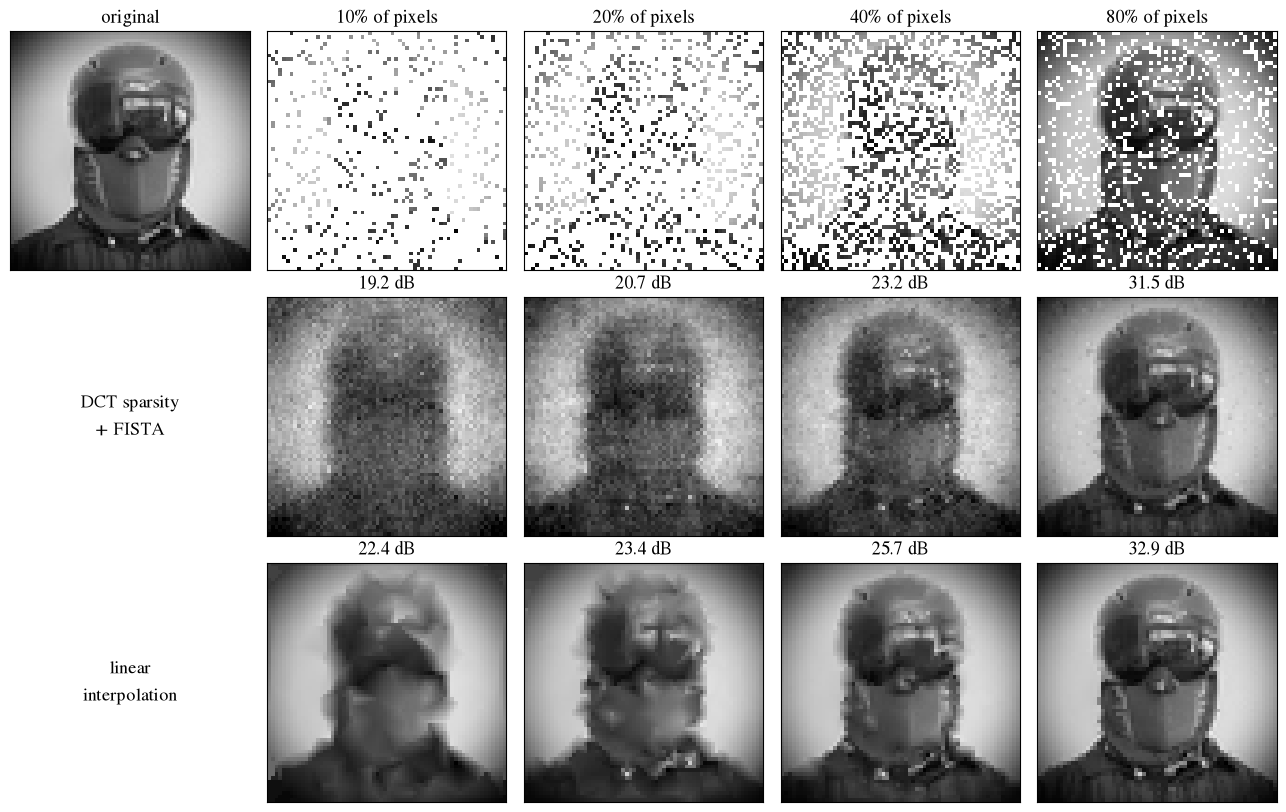

In [7]:
def plot_portrait_fista():
    k = len(RATES)
    fig, ax = plt.subplots(3, k + 1, figsize=(2.6 * (k + 1), 8.2))
    ax[0, 0].imshow(img, cmap='gray', vmin=0, vmax=1); ax[0, 0].set_title('original')
    ax[1, 0].axis('off'); ax[2, 0].axis('off')
    ax[1, 0].text(0.5, 0.5, 'DCT sparsity\n+ FISTA', ha='center', va='center', fontsize=13,
                  transform=ax[1, 0].transAxes)
    ax[2, 0].text(0.5, 0.5, 'linear\ninterpolation', ha='center', va='center', fontsize=13,
                  transform=ax[2, 0].transAxes)
    for j, rate in enumerate(RATES, start=1):
        r = results[rate]
        shown = np.ma.masked_where(~r['mask'], img)       # unmeasured pixels are masked (drawn blank)
        ax[0, j].imshow(np.ones_like(img), cmap='gray', vmin=0, vmax=1, alpha=0.0)
        ax[0, j].imshow(shown, cmap='gray', vmin=0, vmax=1)
        ax[0, j].set_title(f'{100*rate:.0f}% of pixels')
        ax[1, j].imshow(r['x'], cmap='gray', vmin=0, vmax=1)
        ax[1, j].set_title(f"{r['psnr']:.1f} dB")
        ax[2, j].imshow(r['x_lin'], cmap='gray', vmin=0, vmax=1)
        ax[2, j].set_title(f"{r['psnr_lin']:.1f} dB")
    for a in ax.ravel():
        a.set_xticks([]); a.set_yticks([]); a.grid(False)
        if not a.axison:
            continue
        for sp in a.spines.values():
            sp.set_color(fg())
    plt.tight_layout()


save_dual(plot_portrait_fista, 'cs_portrait_fista', FIG)
plt.show()

**How to read this figure.** The top-left panel is the original 64×64
portrait. The rest of the top row shows what we actually measured at 10 %,
20 %, 40 % and 80 % of the pixels: measured pixels carry their true gray
value, unmeasured pixels are left blank (they show as the white
background). The middle row is the FISTA reconstruction from those pixels
and the bottom row is linear interpolation of the same pixels. The title
above each reconstruction is its PSNR against the original; higher is better.

**What it shows.** FISTA goes from 19.2 dB (10 %) through 20.7 and 23.2 dB to
31.5 dB (80 %). At low rates its result is grainy: the head and helmet are
recognisable, but the fine detail is replaced by speckle, because FISTA
spends its few coefficients on a mix of cosine patterns that all fit the
measured pixels. Interpolation scores 22.4, 23.4, 25.7 and 32.9 dB. Its
errors look different (smeared, triangular patches instead of speckle), but
they are smaller. The lesson: for clean pixel samples of a smooth image, a
simple local prior beats a global sparsity prior. Compressed sensing is not
automatically the best way to fill in missing pixels.

## 2. Choosing $\lambda$

Too small and the solver fits the measured pixels with any coefficient
pattern (no prior left); too large and it keeps only the coarsest DCT
modes (blur). There is a broad sweet spot in between.

The next cell draws one new random mask at `RATE_SWEEP` and solves the lasso
for each of the 17 values in `LAM_SWEEP` (log-spaced from $10^{-4}$ to $1$).
For each $\lambda$ it stores the PSNR and the number of nonzero
coefficients $\|\hat{\boldsymbol{s}}\|_0$, then checks that the PSNR peaks
inside the range and that larger $\lambda$ always gives a sparser solution.

lambda sweep at 20%: best lambda = 3.2e-02, PSNR 21.1 dB


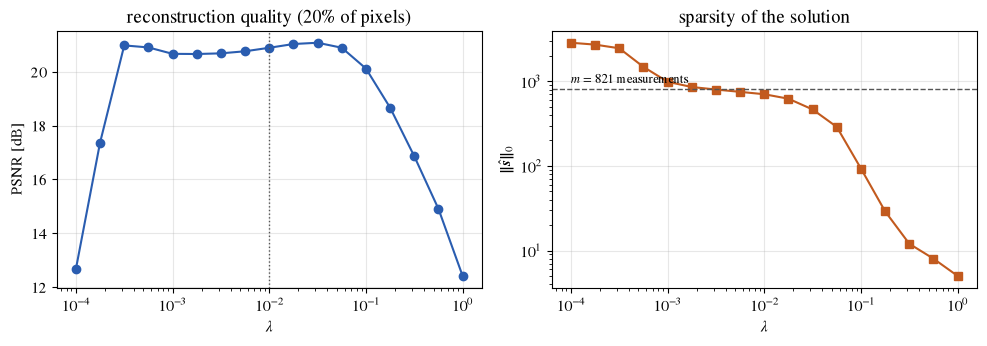

In [8]:
mask_s = rng.random(img.shape) < RATE_SWEEP
y_s = img[mask_s]
sweep = []
for lam in LAM_SWEEP:
    s_hat = fista_pixels(y_s, mask_s, lam)
    sweep.append((psnr(np.clip(idctn(s_hat, norm='ortho'), 0, 1), img), np.count_nonzero(s_hat)))
sweep = np.array(sweep)                                   # columns: PSNR [dB], ||s||_0
best = LAM_SWEEP[np.argmax(sweep[:, 0])]
print(f"lambda sweep at {100*RATE_SWEEP:.0f}%: best lambda = {best:.1e}, PSNR {sweep[:,0].max():.1f} dB")
assert sweep[:, 0].max() > sweep[0, 0] + 1 and sweep[:, 0].max() > sweep[-1, 0] + 1, \
    "the PSNR curve must peak in the interior of the sweep"
assert np.all(np.diff(sweep[:, 1]) <= 0), "larger lambda must give sparser coefficients"


def plot_lambda_sweep():
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].semilogx(LAM_SWEEP, sweep[:, 0], 'o-', color='C0')
    ax[0].axvline(LAM, color=muted(), ls=':', lw=1)
    ax[0].set(xlabel=r'$\lambda$', ylabel='PSNR [dB]',
              title=f'reconstruction quality ({100*RATE_SWEEP:.0f}% of pixels)')
    ax[1].loglog(LAM_SWEEP, sweep[:, 1], 's-', color='C1')
    ax[1].axhline(mask_s.sum(), color=muted(), ls='--', lw=1)
    ax[1].text(LAM_SWEEP[0], mask_s.sum() * 1.15, f'$m$ = {mask_s.sum()} measurements', fontsize=9)
    ax[1].set(xlabel=r'$\lambda$', ylabel=r'$\|\hat{\boldsymbol{s}}\|_0$', title='sparsity of the solution')
    plt.tight_layout()


save_dual(plot_lambda_sweep, 'cs_portrait_lambda', FIG)
plt.show()

**How to read this figure.** Both panels share a logarithmic $\lambda$ axis.
Left: PSNR of the reconstruction from 20 % of the pixels; the dotted vertical
line marks the value `LAM` = 0.01 used in Section 1. Right: the number of
nonzero DCT coefficients $\|\hat{\boldsymbol{s}}\|_0$ on a log scale; the
dashed horizontal line is the number of measurements, $m$ = 821 for this mask.

**What it shows.** The best value in the sweep is $\lambda$ = 3.2e-02 with
21.1 dB. The PSNR curve has a wide plateau of roughly 21 dB that covers more
than two decades of $\lambda$, and `LAM` = 0.01 sits on it, so the choice in
Section 1 was reasonable. At the left end the PSNR drops sharply: there are
more nonzero coefficients than measurements, so the solver can fit the
measured pixels exactly and the prior no longer controls the missing ones. At
the right end the PSNR drops again: only a handful of coefficients survive
and the image is reduced to a blur. Around `LAM` and the best value the
number of nonzeros lies below $m$, which is what a useful sparse solution
should do.

## 3. So what is compressed sensing for? A single-pixel camera in low light

The comparison above assumed we *can* read individual pixels cheaply and
cleanly. A single-pixel camera cannot: it has one detector behind a
micromirror array. To "read a pixel" it must turn on one mirror and collect
the light of that one pixel; to take a compressed-sensing measurement it turns
on a random half of the mirrors and collects the light of about $n/2$ pixels
at once.

Every reading of the detector carries the same additive noise $\sigma$
(dark current and read-out noise, the limiting factor for infrared and
terahertz detectors), measured in units of the light from one fully bright
pixel. With the same number $m$ of readings:

* **scanning camera**: $m$ single-pixel readings, $y_i=x_{j_i}+\sigma\varepsilon_i$,
  then linear interpolation;
* **single-pixel camera**: $m$ random 0/1 mirror patterns
  $y_i=\boldsymbol{b}_i^\top\boldsymbol{x}+\sigma\varepsilon_i$ plus one all-on
  reading $y_0=\mathbf{1}^\top\boldsymbol{x}+\sigma\varepsilon_0$; the
  combination $2y_i-y_0$ is a $\pm1$ pattern measurement, decoded by FISTA with
  the DCT prior.

Here $x_{j_i}$ is the brightness of the $i$-th scanned pixel, $\varepsilon_i$
are independent standard normal numbers, $\boldsymbol{b}_i\in\{0,1\}^n$ is
the $i$-th mirror pattern (1 = mirror on) and $\mathbf{1}$ is the all-ones
vector.

**The $2y_i-y_0$ trick.** A 0/1 pattern has a large positive mean, so every
reading is dominated by the total brightness of the scene and carries little
information about the details. Subtracting the all-on reading removes that
common part:

$$2y_i-y_0=(2\boldsymbol{b}_i-\mathbf{1})^\top\boldsymbol{x}+\sigma(2\varepsilon_i-\varepsilon_0).$$

The new pattern $2\boldsymbol{b}_i-\mathbf{1}$ has entries $\pm1$ and mean
zero, which is the well-behaved random matrix compressed sensing likes. Only
one extra reading ($y_0$) is needed for all $m$ patterns.

A pattern reading collects $\sim n/2$ pixels of light against the same
$\sigma$: that is the *multiplex advantage*, and sparsity is what lets us
undo the mixing.

The next cell sets up the experiment at 20 % of $n$ readings (`RATE_SPC`).
`B` is the $m\times n$ matrix whose rows are the 0/1 patterns
$\boldsymbol{b}_i^\top$, and `Bpm` $=2\mathbf{B}-\mathbf{1}$ holds the $\pm1$
patterns. Now $\boldsymbol{\Phi}=\mathbf{B}_{\pm}\boldsymbol{\Psi}$ is a dense
matrix and its norm is no longer 1, so the step constant is computed as
$L=\|\mathbf{B}_{\pm}\|_2^2$ (`L_spc`). `fista_patterns` is the same FISTA
loop with this $\boldsymbol{\Phi}$ and weight `LAM_SPC`. `interp_pixels` is
the interpolation baseline for the scanning camera, on its own random set of
`m_spc` pixel positions.

In [9]:
RATE_SPC = 0.20
SIGMAS = [0.0, 0.03, 0.1, 0.2, 0.3, 0.5]
LAM_SPC = 3.0
m_spc = int(RATE_SPC * n)
B = (rng.random((m_spc, n)) < 0.5).astype(float)          # mirror patterns (0 = off, 1 = on)
Bpm = 2 * B - 1                                           # +-1 patterns seen after the 2 y_i - y_0 trick
L_spc = np.linalg.norm(Bpm, 2) ** 2                       # step constant = largest singular value squared
pix_idx = rng.choice(n, m_spc, replace=False)             # pixels read by the scanning camera
mask_spc = np.zeros(n, bool); mask_spc[pix_idx] = True; mask_spc = mask_spc.reshape(img.shape)
xs = img.ravel()


def fista_patterns(y, n_iter=400):
    s = np.zeros(img.shape); z = s.copy(); t = 1.0
    for _ in range(n_iter):
        r = Bpm @ idctn(z, norm='ortho').ravel() - y                          # Phi z - y
        v = z - dctn((Bpm.T @ r).reshape(img.shape), norm='ortho') / L_spc    # z - Phi^T r / L
        s_new = soft_threshold(v, LAM_SPC / L_spc)
        t_new = (1 + np.sqrt(1 + 4 * t * t)) / 2
        z = s_new + (t - 1) / t_new * (s_new - s)
        s, t = s_new, t_new
    return np.clip(idctn(s, norm='ortho'), 0, 1)


def interp_pixels(vals):
    P, Q = np.argwhere(mask_spc), np.argwhere(np.ones_like(mask_spc))
    lin = griddata(P, vals, Q, method='linear'); near = griddata(P, vals, Q, method='nearest')
    return np.clip(np.where(np.isnan(lin), near, lin).reshape(img.shape), 0, 1)

For each noise level $\sigma$ in `SIGMAS` we simulate both cameras with the
same budget of `m_spc` readings and the same $\sigma$ per reading, using a
separate random generator for the noise. The scanning camera's noisy pixels
go to `interp_pixels`; the single-pixel camera's readings are combined as
$2y_i-y_0$ and decoded by `fista_patterns`. The asserts check that clean
interpolation wins at $\sigma=0$, that CS wins by more than 5 dB at
$\sigma=0.3$, and that the CS result varies by less than 2.5 dB over all
$\sigma$.

In [10]:
noise_rng = np.random.default_rng(SEED + 1)
spc = {}
for sig in SIGMAS:
    y_scan = img[mask_spc] + sig * noise_rng.standard_normal(m_spc)       # one pixel per reading
    y0 = xs.sum() + sig * noise_rng.standard_normal()                     # all mirrors on
    y_pat = 2 * (B @ xs + sig * noise_rng.standard_normal(m_spc)) - y0    # 2 y_i - y_0: +-1 patterns
    x_scan, x_spc = interp_pixels(y_scan), fista_patterns(y_pat)
    spc[sig] = dict(scan=x_scan, spc=x_spc, p_scan=psnr(x_scan, img), p_spc=psnr(x_spc, img))
    print(f"sigma {sig:4.2f}: scanning camera + interpolation {spc[sig]['p_scan']:5.1f} dB | "
          f"single-pixel camera + CS {spc[sig]['p_spc']:5.1f} dB")

assert spc[0.0]['p_scan'] > spc[0.0]['p_spc'], "noise-free: interpolation of clean pixels wins"
assert spc[0.3]['p_spc'] > spc[0.3]['p_scan'] + 5, "noisy detector: multiplexed CS must win clearly"
p_spc_all = [spc[sg]['p_spc'] for sg in SIGMAS]
assert max(p_spc_all) - min(p_spc_all) < 2.5, "the CS camera must be nearly insensitive to detector noise"
SIG_SHOW = 0.3

sigma 0.00: scanning camera + interpolation  23.0 dB | single-pixel camera + CS  20.6 dB


sigma 0.03: scanning camera + interpolation  22.6 dB | single-pixel camera + CS  20.6 dB


sigma 0.10: scanning camera + interpolation  19.5 dB | single-pixel camera + CS  20.6 dB


sigma 0.20: scanning camera + interpolation  15.5 dB | single-pixel camera + CS  20.6 dB


sigma 0.30: scanning camera + interpolation  13.3 dB | single-pixel camera + CS  20.6 dB


sigma 0.50: scanning camera + interpolation  10.2 dB | single-pixel camera + CS  20.6 dB


**Reading the numbers.** Without noise the scanning camera wins, 23.0 dB
against 20.6 dB, which repeats the finding of Section 1. As $\sigma$ grows,
the scanning camera falls quickly (19.5 dB at $\sigma=0.1$, 13.3 dB at
$\sigma=0.3$, 10.2 dB at $\sigma=0.5$), while the single-pixel camera stays at
20.6 dB for every $\sigma$ in the sweep. The reason: a pixel reading carries
at most one unit of light, so noise of size 0.3 is huge relative to it,
whereas a pattern reading carries the light of about half the scene, so the
same noise is tiny in comparison. All asserts pass.

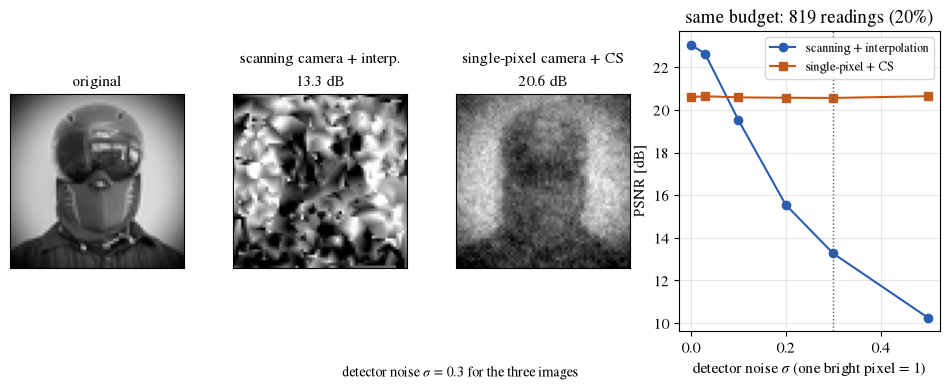

In [11]:
def plot_single_pixel():
    fig = plt.figure(figsize=(12, 3.9))
    gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 1.5], wspace=0.25)
    ims = [(img, 'original'),
           (spc[SIG_SHOW]['scan'], f"scanning camera + interp.\n{spc[SIG_SHOW]['p_scan']:.1f} dB"),
           (spc[SIG_SHOW]['spc'], f"single-pixel camera + CS\n{spc[SIG_SHOW]['p_spc']:.1f} dB")]
    for j, (im, ttl) in enumerate(ims):
        a = fig.add_subplot(gs[j]); a.imshow(im, cmap='gray', vmin=0, vmax=1)
        a.set_title(ttl, fontsize=11); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    a = fig.add_subplot(gs[3])
    a.plot(SIGMAS, [spc[sg]['p_scan'] for sg in SIGMAS], 'o-', color='C0', label='scanning + interpolation')
    a.plot(SIGMAS, p_spc_all, 's-', color='C1', label='single-pixel + CS')
    a.axvline(SIG_SHOW, color=muted(), ls=':', lw=1)
    a.set(xlabel=r'detector noise $\sigma$ (one bright pixel = 1)', ylabel='PSNR [dB]',
          title=f'same budget: {m_spc} readings ({100*RATE_SPC:.0f}%)')
    a.legend(fontsize=9)
    fig.suptitle(f'detector noise $\\sigma$ = {SIG_SHOW} for the three images', fontsize=10, y=0.02)


save_dual(plot_single_pixel, 'cs_single_pixel_lowlight', FIG)
plt.show()

**How to read this figure.** The three images on the left are, in order, the
original portrait, the scanning-camera reconstruction and the single-pixel
camera reconstruction, both at detector noise $\sigma=0.3$ (the caption
under the images); their PSNR is in the titles. The right panel shows PSNR
against $\sigma$ for both cameras with the same budget of 819 readings
(20 % of the pixels). Blue circles are scanning plus interpolation, orange
squares are single-pixel plus CS, and the dotted vertical line marks the
$\sigma=0.3$ shown on the left.

**What it shows.** At $\sigma=0.3$ the scanning camera gives 13.3 dB: the
noisy pixel values are interpolated faithfully, so the noise is spread into
large blotches and the face disappears. The single-pixel camera gives
20.6 dB: a grainy but clearly recognisable head and shoulders. In the right
panel the blue curve starts higher (23.0 dB at $\sigma=0$) but crosses below
the flat orange curve between $\sigma=0.03$ and $\sigma=0.1$. This is where
compressed sensing earns its place: when each measurement is expensive or
noisy, and a mixed (multiplexed) measurement collects much more signal than
a single pixel, sparsity lets us undo the mixing.

## Summary

* Random pixels + a DCT sparsity prior + FISTA reconstruct the portrait far
  better than filling the gaps with no prior at all.
* **But** plain linear interpolation of the same pixels is a few dB better
  still. A *global* DCT prior is weaker than *local* smoothness when the
  measurements are pixels of a smooth image. Compressed sensing earns its keep
  when the signal is genuinely sparse and the alternative is sub-Nyquist
  guessing (`cs_uniform_vs_random`), or when the measurements are not pixels at
  all (MRI Fourier samples, single-pixel-camera patterns), where interpolation
  has nothing to interpolate.
* Section 3 measures the second case: with a single noisy detector, random
  mirror patterns collect half the scene's light per reading, and at
  detector noise $\sigma=0.3$ the CS camera beats pixel scanning by a wide
  margin while staying almost insensitive to $\sigma$.
* The image is only *compressible*, not sparse, so quality degrades smoothly
  as the sampling rate falls. There is no sharp phase transition as in
  `cs_phase_transition`, where the signal was exactly $k$-sparse.
* $\lambda$ trades data fit for sparsity; the optimum is broad, and the
  number of nonzero coefficients it selects stays below the number of
  measurements.

## Try this

All changes go in the "Parameters (edit these)" cell; rerun the notebook
from the top afterwards.

1. **Use the best $\lambda$.** Set `LAM = 0.032` (the best value from the
   sweep). The Section 1 PSNRs should change only a little, because both
   values sit on the broad plateau. Does the gap to interpolation close?
2. **Fewer pixels.** Add `0.05` to the front of `RATES`. Expect FISTA and
   interpolation to both drop further, with the image barely recognisable.
   Check whether the "interpolation leads by 0–4 dB" assert still holds.
3. **Stop FISTA early.** Set `N_ITER = 50`. The convergence assert compares
   the objective with its value 50 iterations earlier, so it is expected to
   fail: this shows what the assert protects against. Try `N_ITER = 100` too.
4. **Another random draw.** Change `SEED` to 1 or 2. The individual PSNR
   values move a little, but the ordering (mean fill below FISTA
   below interpolation, and CS winning in noise) should stay the same.